# Week 2 Task 4 — Channel effectiveness, measured

This notebook follows the Week 2 assignment brief and keeps each task in a separate file.

In [14]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

path = Path('week2/assignments/data/channel_trials.csv')
if not path.exists():
    path = Path('assignments/data/channel_trials.csv')
if not path.exists():
    path = Path('d:/7_Semester/data-visualization/week2/assignments/data/channel_trials.csv')
trial_df = pd.read_csv(path)
print(trial_df.head())


   trial   channel  true_ratio  value_large  value_small  reader_estimate  \
0      1  position        0.15           76        11.40              NaN   
1      2  position        0.25           59        14.75              NaN   
2      3  position        0.40           76        30.40              NaN   
3      4  position        0.55           68        37.40              NaN   
4      5  position        0.70           61        42.70              NaN   

   absolute_error  
0             NaN  
1             NaN  
2             NaN  
3             NaN  
4             NaN  


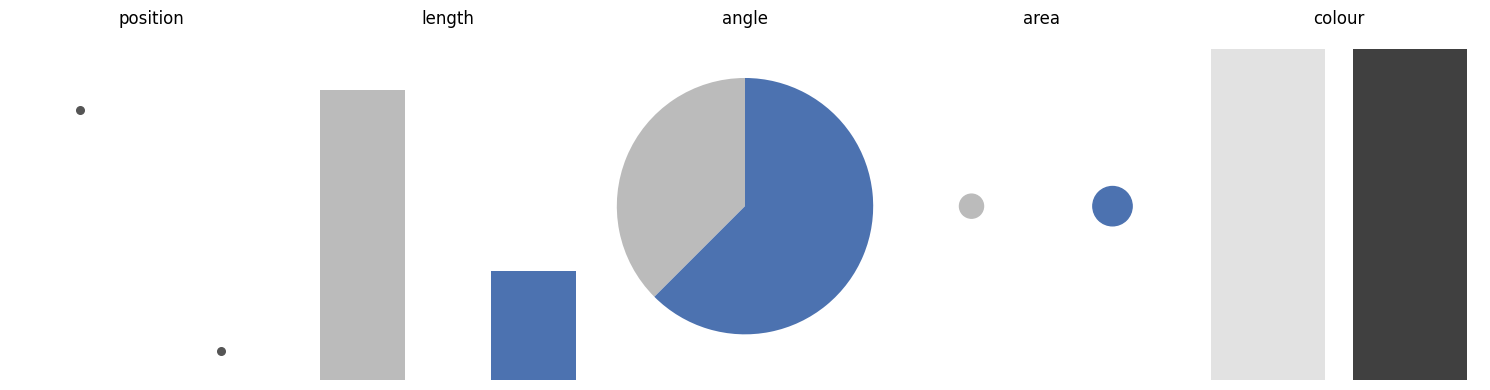

In [15]:
def encode_position(ax, large, small):
    ax.scatter([0, 1], [large, small], s=30, color='#555555')
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(min(large, small) * 0.8, max(large, small) * 1.2)
    ax.axis('off')

def encode_length(ax, large, small):
    ax.bar([0, 1], [large, small], width=0.5, color=['#bbbbbb', '#4c72b0'])
    ax.set_ylim(0, max(large, small) * 1.2)
    ax.axis('off')

def encode_angle(ax, large, small):
    theta = np.linspace(0, 2*np.pi, 100)
    ax.pie([small, large-small], radius=1.0, colors=['#bbbbbb', '#4c72b0'], startangle=90)
    ax.axis('equal'); ax.axis('off')

def encode_area(ax, large, small):
    ax.scatter([0, 1], [0, 0], s=[small*10, large*10], color=['#bbbbbb', '#4c72b0'])
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-1, 1)
    ax.axis('off')

def encode_colour(ax, large, small):
    ax.bar([0, 1], [1, 1], color=[plt.cm.Greys(0.2), plt.cm.Greys(0.8)], width=0.8)
    ax.axis('off')

fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for ax, func in zip(axes, [encode_position, encode_length, encode_angle, encode_area, encode_colour]):
    func(ax, 80, 30)
    ax.set_title(func.__name__.replace('encode_', ''))
plt.tight_layout(); plt.show()


In [16]:
# A real participant should record their estimate in reader_estimate and then the absolute error is computed.
# Keep the order shuffled and do not tell the participant the true answers until the end.
# This cell also creates a CSV template that you can fill with real responses and rerun.
results_path = Path('channel_results.csv')
if results_path.exists():
    results = pd.read_csv(results_path)
else:
    results = trial_df.copy()
    results['reader_estimate'] = pd.NA
    results['absolute_error'] = pd.NA
    results.to_csv(results_path, index=False)
    print(f'Created a template at {results_path}. Fill in reader_estimate and rerun this notebook.')
results.head()

,trial,channel,true_ratio,value_large,value_small,reader_estimate,absolute_error
0,1,position,0.15,76,11.40,NaN,NaN
1,2,position,0.25,59,14.75,NaN,NaN
2,3,position,0.40,76,30.40,NaN,NaN
3,4,position,0.55,68,37.40,NaN,NaN
4,5,position,0.70,61,42.70,NaN,NaN


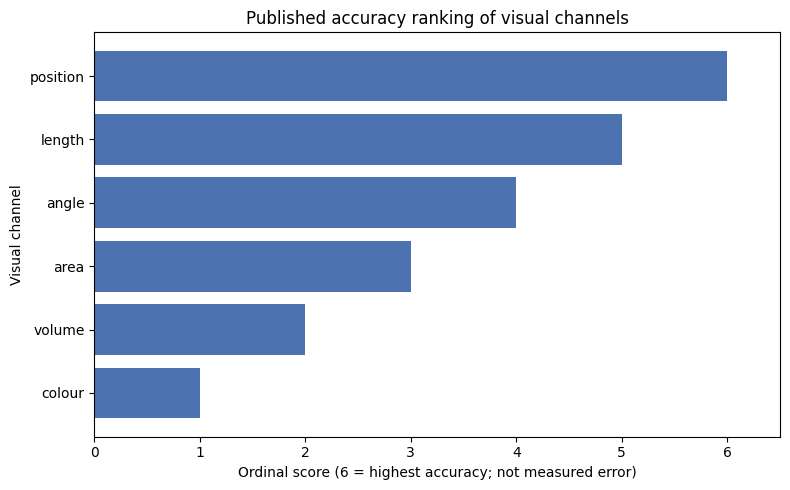

Measured error ranking not shown: enter real estimates in channel_results.csv to calculate it.


In [19]:
# Show the published perceptual-accuracy order even before participant responses are collected.
published_order = ['position', 'length', 'angle', 'area', 'volume', 'colour']
ordinal_score = pd.Series(range(len(published_order), 0, -1), index=published_order)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(ordinal_score.index, ordinal_score.values, color='#4c72b0')
ax.invert_yaxis()
ax.set_xlim(0, 6.5)
ax.set_title('Published accuracy ranking of visual channels')
ax.set_xlabel('Ordinal score (6 = highest accuracy; not measured error)')
ax.set_ylabel('Visual channel')
plt.tight_layout()
plt.show()

# Participant results are separate: compute their measured mean absolute error only when estimates exist.
if 'reader_estimate' in results.columns:
    cleaned = results['reader_estimate'].map(
        lambda value: pd.to_numeric(str(value).replace('%', '').strip(), errors='coerce')
    )
    valid_results = results.loc[cleaned.notna()].copy()
    if not valid_results.empty:
        valid_results['reader_estimate'] = cleaned.loc[cleaned.notna()]
        valid_results['absolute_error'] = (
            valid_results['reader_estimate'] / 100 - valid_results['true_ratio']
        ).abs()
        channel_error = valid_results.groupby('channel')['absolute_error'].mean().sort_values()
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.bar(channel_error.index, channel_error.values, color='#55a868')
        ax.set_title('Your measured mean absolute error by channel')
        ax.set_xlabel('Channel')
        ax.set_ylabel('Mean absolute error (lower is better)')
        plt.tight_layout()
        plt.show()
    else:
        print('Measured error ranking not shown: enter real estimates in channel_results.csv to calculate it.')
else:
    print('Measured error ranking not shown: enter real estimates in channel_results.csv to calculate it.')

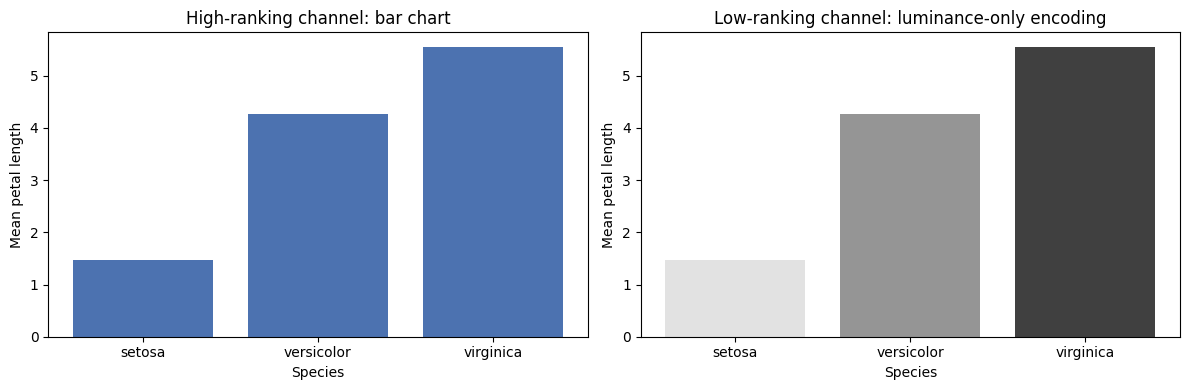

In [18]:
# Using iris.csv, the same data can be encoded with a stronger channel (position) or a weaker one (colour). The point is not aesthetics but decoding accuracy.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

path = Path('week2/assignments/data/iris.csv')
if not path.exists():
    path = Path('assignments/data/iris.csv')
if not path.exists():
    path = Path('d:/7_Semester/data-visualization/week2/assignments/data/iris.csv')

iris = pd.read_csv(path)
by_species = iris.groupby('species')['petal_length'].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(by_species.index, by_species.values, color='#4c72b0')
axes[0].set_title('High-ranking channel: bar chart')
axes[0].set_xlabel('Species')
axes[0].set_ylabel('Mean petal length')

colors = plt.cm.Greys(np.linspace(0.2, 0.8, len(by_species)))
axes[1].bar(by_species.index, by_species.values, color=colors)
axes[1].set_title('Low-ranking channel: luminance-only encoding')
axes[1].set_xlabel('Species')
axes[1].set_ylabel('Mean petal length')
plt.tight_layout(); plt.show()

In [ ]:
# The published ranking suggests position and length are more accurate than area or colour. With only a handful of trials, the experiment cannot support a strong statistical claim, but it still helps calibrate the design choices.
